In [2]:
import sys, cv2, torch, easyocr, paddle, paddleocr

print("Python", sys.version.split()[0])
print("OpenCV", cv2.__version__)
print("PyTorch", torch.__version__)
print("EasyOCR", easyocr.__version__)
print("PaddlePaddle", paddle.__version__)
print("PaddleOCR", paddleocr.__version__)

c:\D into C(06-22-2026_18-36)\my_files\university\4.1\ШІ\лаб_3\AI_lab3_text_recognition\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
c:\D into C(06-22-2026_18-36)\my_files\university\4.1\ШІ\лаб_3\AI_lab3_text_recognition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.


Python 3.12.13
OpenCV 4.10.0
PyTorch 2.15.0+cpu
EasyOCR 1.7.2
PaddlePaddle 3.3.1
PaddleOCR 3.4.1


## 1. Імпорт бібліотек

In [34]:
import os, re, time, hashlib, unicodedata, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import requests
import json
import easyocr
from paddleocr import PaddleOCR
from datasets import load_dataset, Image as HFImage
from PIL import Image, ImageDraw, ImageFont, ExifTags, ImageOps
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr
from pillow_heif import register_heif_opener
register_heif_opener()

warnings.filterwarnings("ignore")

## 2. Персональні параметри та налаштування

In [4]:
STUDENT = "Твердун Т.А."
VARIANT = 11
STUDENT_ID = 44
SEED = 1000 * VARIANT + STUDENT_ID
rng = np.random.default_rng(SEED)

FONTS = [
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/times.ttf",
    "C:/Windows/Fonts/calibri.ttf",
    "C:/Windows/Fonts/georgia.ttf",
    "C:/Windows/Fonts/verdana.ttf",
    "C:/Windows/Fonts/tahoma.ttf",
]

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print("SEED =", SEED)

SEED = 11044


## 3. Синтетичний набір даних

### 3.1. Завантаження тексту твору

In [5]:
resp = requests.get(
    "https://uk.wikisource.org/w/index.php",
    params={"title": "Лісова пісня", "action": "raw"},
    headers={"User-Agent": "lab3-ocr-student"},
    timeout=30,
)
resp.raise_for_status()
raw = resp.text

print("Characters loaded:", len(raw))
print(raw[:1500])

Characters loaded: 88563
{{заголовок
 | назва      = Лісова пісня
 | автор      = Леся Українка
 | перекладач = 
 | секція     = 
 | попередня  = 
 | наступна   = 
 | рік        =1911 
 | примітки   = 
}}
<poem>
ЛІСОВА ПІСНЯ
Драма-феєрія в 3-х діях
 
СПИС ДІЯЧІВ "ЛІСОВОЇ ПІСНІ"
 
ПРОЛОГ
 
"Той, що греблі рве". 	Русалка. 
Потерчата (двоє).	        Водяник.
 
ДІЯ І
 
Дядько Лев. 	      Перелесник. 
Лукаш. 	              Пропасниця (без мови). 
Русалка. 	              Потерчата. 
Лісовик. 	              Куць.
Мавка.
 
ДІЯ II
 
Мати Лукашева.	Килина.
Лукаш.	                 Русалка.
Дядько Лев.                "Той, що в скалі
Мавка.                        сидить".
Русалка Польова.     Перелесник.
 
ДІЯ III
 
Мавка.                            Хлопчик.
Лісовик.                          Лукаш.
Куць.                               Діти Килинині
Злидні.                            (без мови).
Мати Лукашева.             Доля.
Килина.                           Перелесник.
 
ПРОЛОГ
 
Старезний, густ

### 3.2. Очищення тексту

In [6]:
text = raw.split("<poem>")[1].split("</poem>")[0]
text = text[text.index("Старезний"):]

def is_speaker(line):
    words = re.sub(r"[^\w\s]", "", line).split()
    singles = sum(len(w) == 1 for w in words)
    return singles >= 3 and all(len(w) <= 2 for w in words)

kept = [l for l in text.splitlines() if not is_speaker(l) and not l.strip().isupper()]
text = " ".join(kept)
text = re.sub(r"\([^)]*\)", " ", text)
text = " ".join(text.split())

print("Characters after cleaning:", len(text))
print(text[:800])

Characters after cleaning: 68044
Старезний, густий, предковічний ліс на Волині. Посеред лісу простора галява з плакучою березою і з великим прастарим дубом. Галява скраю переходить в куп'я та очерети, а в одному місці в яро-зелену драговину - то береги лісового озера, що утворилося з лісового струмка. Струмок той вибігає з гущавини лісу, впадає в озеро, потім, по другім боці озера, знов витікає і губиться в хащах. Саме озеро - тиховоде, вкрите ряскою та лататтям, але з чистим плесом посередині. Містина вся дика, таємнича, але не понура, - повна ніжної, задумливої поліської краси. Провесна. По узліссі і на галяві зеленіє перший ряст і цвітуть проліски та сон-трава. Дерева ще безлисті, але вкриті бростю, що от-от має розкритись. На озері туман то лежить пеленою, то хвилює од вітру, то розривається, одкриваючи блідо-блакитну


### 3.3. Поділ на речення

In [7]:
sentences = re.split(r'(?<=[.!?…])\s+|(?<=[.!?…]")\s+', text)
sentences = [s.lstrip(" ,;:-") for s in sentences]
corpus = list(dict.fromkeys(s for s in sentences if 20 <= len(s) <= 70))

with open("corpus.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(corpus))

print("Sentences total:", len(sentences))
print("Sentences in corpus (20-70 chars):", len(corpus))
for s in corpus[:10]:
    print(s)

Sentences total: 1783
Sentences in corpus (20-70 chars): 803
Старезний, густий, предковічний ліс на Волині.
Дерева ще безлисті, але вкриті бростю, що от-от має розкритись.
З гір на долину біжу, стрибаю, рину!
Чого ти тута блудиш?
Чого зо сну нас будиш?
Чого ж ти тут шугаєш?
Зіб'ю всю вашу воду, таки знайду ту вроду!
Печера в нас маленька, що збудувала ненька.
Убога наша хатка, бо в нас немає татка...
Нехай до мене зрине!


### 3.4. Вибір 40 речень

In [8]:
N_LINES = 40
lines = [str(s) for s in rng.choice(corpus, size=N_LINES, replace=False)]

print("Selected lines:", len(lines))
for s in lines:
    print(s)

Selected lines: 40
Який-бо ти, дідусю, став суворий!
Прохолодитись треба.
Хай Змія-цариця мене скарає, якщо се неправда!
Вже й сон-трава перецвітати стала.
Я ледь що вибрався живий на берег, і рибу розгубив...
Самій увечері в сій пущі сумно.
Мені здається, що жила я завжди...
В очеретах заблимали два бродячі вогники.
Я міркував би, що вже б тобі не тра верби на зиму.
Ти б іще зібрав сюди усіх відьом із лісу.
Якби ж воно такеє говорило, що тямить, ну, то й слухав би, а то...
Ви ж про Царівну мали.
Я не маю сили покинути її...
Чи бач, як знітилась невірна пара, відьомський накоренок!
Ні, се так добре - умерти, як летюча зірка...
"Той, що в скалі сидить" виходить і подається до Мавки.
бач, вона така суха, і все рипить, все згадує про зиму...
Перелесник здригнувся, прудким рухом кинувся геть і зник у лісі.
Вже з вирію поприлітали гості.
Ну, я піду - управлюся тим часом з дробиною.
Відай, ви, дядьку, щось тут проминули.
Чи у людей паруються надовго?
Дяка щирая тобі, ніченько-чарівниченько, 

### 3.5. Малювання рядка тексту

Image shape (height, width): (54, 528)


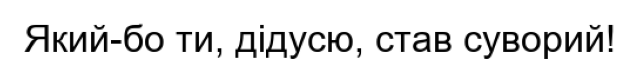

In [9]:
def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

example = render_line(lines[0], FONTS[0])
print("Image shape (height, width):", example.shape)

plt.figure(figsize=(8, 1))
plt.imshow(example, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### 3.6. Нерівне освітлення

level  0 %: right edge background = 255
level 15 %: right edge background = 216
level 30 %: right edge background = 178
level 45 %: right edge background = 140
level 60 %: right edge background = 102
level 75 %: right edge background = 63


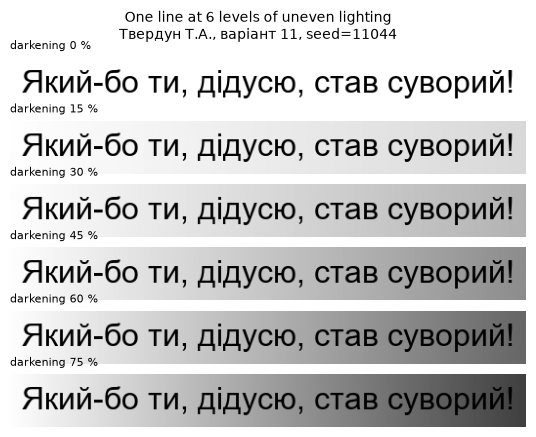

In [10]:
LEVELS = [0, 15, 30, 45, 60, 75]

def degrade(img, level):
    h, w = img.shape
    light = np.linspace(1.0, 1.0 - level / 100, w)
    out = img.astype(np.float32) * light
    return np.clip(out, 0, 255).astype(np.uint8)

for lvl in LEVELS:
    print(f"level {lvl:2d} %: right edge background = {degrade(example, lvl)[0, -1]}")

fig, axes = plt.subplots(len(LEVELS), 1, figsize=(8, 0.8 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    ax.imshow(degrade(example, lvl), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"darkening {lvl} %", fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"One line at {len(LEVELS)} levels of uneven lighting\n"
             f"{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.7. Генерація набору

In [11]:
FACTOR = "light"

records = []
for i, sentence in enumerate(lines):
    font = FONTS[i % len(FONTS)]
    size = int(rng.integers(22, 36))
    clean = render_line(sentence, font, size=size)
    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, lvl))
        records.append({"id": i, "level": lvl, "path": path, "gt": sentence,
                        "font": os.path.basename(font), "size": size})

ds = pd.DataFrame(records)
print("Images saved:", len(ds))
ds.head(8)

Images saved: 240


,id,level,path,gt,font,size
0,0,0,data/000_light_0.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
1,0,15,data/000_light_15.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
2,0,30,data/000_light_30.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
3,0,45,data/000_light_45.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
4,0,60,data/000_light_60.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
5,0,75,data/000_light_75.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
6,1,0,data/001_light_0.png,Прохолодитись треба.,times.ttf,26
7,1,15,data/001_light_15.png,Прохолодитись треба.,times.ttf,26


### 3.8. Еталон і хеш SHA-256

In [12]:
ds.to_csv("data/ground_truth.csv", index=False, lineterminator="\n")

with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()

print("Ground truth rows:", len(ds))
print("SHA-256:", sha)

Ground truth rows: 240
SHA-256: bb4adf6309f3819522854306055ef5b6cb151dd4dcf21b89cf1da4d77c08c667


## 4. Відкритий набір CORD v2

### 4.1. Завантаження чеків

[2026-11-09 16:05:58,090] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/datasets/naver-clova-ix/cord-v2/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"
[2026-11-09 16:05:58,129] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/naver-clova-ix/cord-v2/7f0115a4b758a71d6473b8d085751692da2fef98/README.md?%2Fdatasets%2Fnaver-clova-ix%2Fcord-v2%2Fresolve%2Fmain%2FREADME.md=&etag=%22b187bb7e7d837a367ccd0862441947ad412c77f7%22 "HTTP/1.1 200 OK"
[2026-11-09 16:05:58,257] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/datasets/naver-clova-ix/cord-v2/resolve/7f0115a4b758a71d6473b8d085751692da2fef98/cord-v2.py "HTTP/1.1 404 Not Found"
[2026-11-09 16:05:59,422] [    INFO] _client.py:1084 - HTTP Request: HEAD https://s3.amazonaws.com/datasets.huggingface.co/datasets/datasets/naver-clova-ix/cord-v2/naver-clova-ix/cord-v2.py "HTTP/1.1 404 Not Found"
[2026-11-09 16:05:59,867] [    INFO] _client.py:

Dataset({
    features: ['image', 'ground_truth'],
    num_rows: 100
})
Receipt 0 size (width, height): (432, 648)


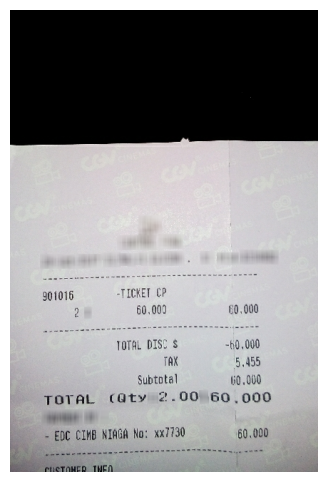

In [13]:
cord = load_dataset(
    "naver-clova-ix/cord-v2",
    data_files={"test": "data/test-*.parquet"},
    split="test",
)
cord = cord.cast_column("image", HFImage())
print(cord)

receipt = cord[0]["image"]
print("Receipt 0 size (width, height):", receipt.size)

plt.figure(figsize=(4, 6))
plt.imshow(receipt)
plt.axis("off")
plt.show()

### 4.2. Розмітка чека

In [14]:
gt = json.loads(cord[0]["ground_truth"])
print("Keys:", list(gt.keys()))
print("Annotated lines:", len(gt["valid_line"]))

for j, line in enumerate(gt["valid_line"]):
    line_text = " ".join(w["text"] for w in line["words"])
    print(j, line["category"], "|", line_text)

print(gt["valid_line"][1]["words"][0])

Keys: ['gt_parse', 'meta', 'valid_line', 'roi', 'repeating_symbol', 'dontcare']
Annotated lines: 11
0 menu.num | 901016
1 menu.nm | -TICKET CP
2 menu.cnt | 2
3 menu.price | 60.000
4 menu.itemsubtotal | 60.000
5 sub_total.discount_price | TOTAL DISC $ -60.000
6 sub_total.tax_price | TAX 5.455
7 sub_total.subtotal_price | Subtotal 60.000
8 total.total_price | TOTAL 60.000
9 total.menuqty_cnt | (Qty 2.00
10 total.creditcardprice | EDC CIMB NIAGA No: xx7730 60.000
{'quad': {'x2': 200, 'y3': 406, 'x3': 200, 'y4': 406, 'x1': 146, 'y1': 386, 'x4': 146, 'y2': 386}, 'is_key': 0, 'row_id': 2028655, 'text': '-TICKET'}


### 4.3. Поділ рядків на фрагменти

In [15]:
def word_box(word):
    q = word["quad"]
    xs = [q["x1"], q["x2"], q["x3"], q["x4"]]
    ys = [q["y1"], q["y2"], q["y3"], q["y4"]]
    return min(xs), min(ys), max(xs), max(ys)

def split_line(line):
    words = sorted(line["words"], key=lambda w: (w["row_id"], word_box(w)[0]))
    segments = []
    for w in words:
        if segments:
            prev = segments[-1][-1]
            x0, y0, x1, y1 = word_box(prev)
            gap = word_box(w)[0] - x1
            if w["row_id"] == prev["row_id"] and gap < (y1 - y0):
                segments[-1].append(w)
                continue
        segments.append([w])
    return segments

for j, line in enumerate(gt["valid_line"]):
    parts = [" ".join(w["text"] for w in seg) for seg in split_line(line)]
    print(j, parts)

0 ['901016']
1 ['-TICKET CP']
2 ['2']
3 ['60.000']
4 ['60.000']
5 ['TOTAL DISC $', '-60.000']
6 ['TAX', '5.455']
7 ['Subtotal', '60.000']
8 ['TOTAL', '60.000']
9 ['(Qty 2.00']
10 ['EDC CIMB NIAGA No: xx7730', '60.000']


### 4.4. Фрагменти з усіх чеків

In [16]:
fragments = []
for r, gt_json in enumerate(cord["ground_truth"]):
    receipt_gt = json.loads(gt_json)
    for j, line in enumerate(receipt_gt["valid_line"]):
        for k, seg in enumerate(split_line(line)):
            boxes = [word_box(w) for w in seg]
            fragments.append({
                "receipt": r, "line": j, "seg": k,
                "category": line["category"],
                "gt": " ".join(w["text"] for w in seg),
                "x0": min(b[0] for b in boxes), "y0": min(b[1] for b in boxes),
                "x1": max(b[2] for b in boxes), "y1": max(b[3] for b in boxes),
            })

frags = pd.DataFrame(fragments)
print("All fragments:", len(frags))

frags = frags[frags["gt"].str.len() >= 3].reset_index(drop=True)
print("Fragments with 3+ characters:", len(frags))
frags.head()

All fragments: 1732
Fragments with 3+ characters: 1418


,receipt,line,seg,category,gt,x0,y0,x1,y1
0,0,0,0,menu.num,901016,42,392,92,412
1,0,1,0,menu.nm,-TICKET CP,146,386,222,406
2,0,3,0,menu.price,60.000,174,410,224,430
3,0,4,0,menu.itemsubtotal,60.000,304,410,352,430
4,0,5,0,sub_total.discount_price,TOTAL DISC $,146,457,238,480


### 4.5. Вибір і вирізання 150 фрагментів

In [17]:
N_CORD = 150
idx = rng.choice(len(frags), size=N_CORD, replace=False)
sample = frags.iloc[np.sort(idx)].reset_index(drop=True)
sample["path"] = [f"data/cord/{r:03d}_{j:02d}_{k}.png"
                  for r, j, k in zip(sample["receipt"], sample["line"], sample["seg"])]

os.makedirs("data/cord", exist_ok=True)
for r, group in sample.groupby("receipt"):
    photo = cord[int(r)]["image"].convert("L")
    for row in group.itertuples():
        pad = max(2, round(0.1 * (row.y1 - row.y0)))
        crop = photo.crop((max(0, row.x0 - pad), max(0, row.y0 - pad),
                           min(photo.width, row.x1 + pad), min(photo.height, row.y1 + pad)))
        crop.save(row.path)

sample.to_csv("data/cord_ground_truth.csv", index=False, lineterminator="\n")
print("CORD fragments saved:", len(sample))
print("Receipts used:", sample["receipt"].nunique())
sample.head()

CORD fragments saved: 150
Receipts used: 74


,receipt,line,seg,category,gt,x0,y0,x1,y1,path
0,0,6,0,sub_total.tax_price,TAX,212,482,240,502,data/cord/000_06_0.png
1,1,6,1,total.total_price,91000,539,826,813,867,data/cord/001_06_1.png
2,3,6,1,total.total_price,"11,000",584,798,691,842,data/cord/003_06_1.png
3,4,6,0,menu.nm,CHIKEN KATSU FF,102,625,340,666,data/cord/004_06_0.png
4,5,3,0,sub_total.subtotal_price,SUBTTL,691,2009,1092,2077,data/cord/005_03_0.png


### 4.6. Приклади фрагментів

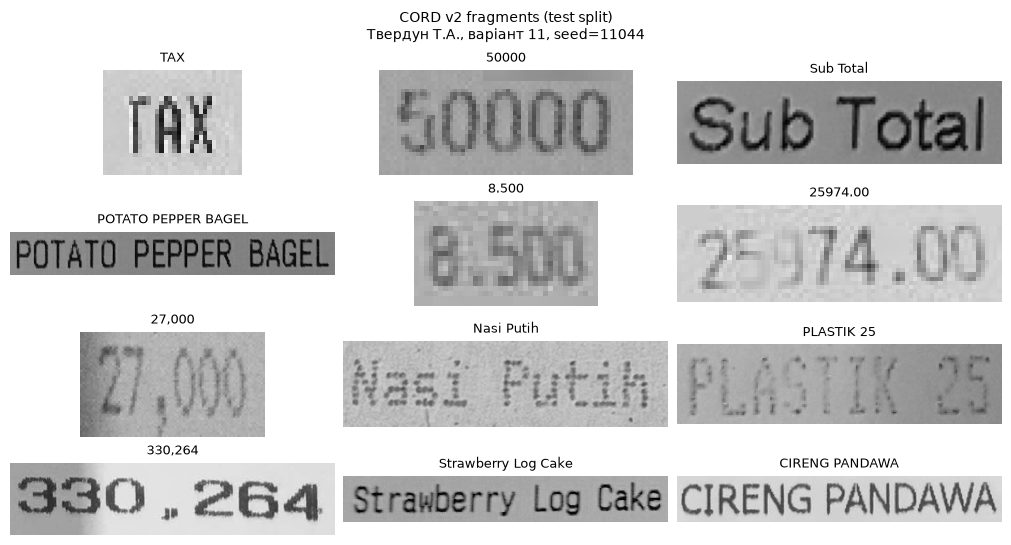

In [18]:
show = sample.iloc[::12].head(12)

fig, axes = plt.subplots(4, 3, figsize=(10, 5.5), layout="constrained")
for ax, row in zip(axes.flat, show.itertuples()):
    img = cv2.imread(row.path, cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(row.gt, fontsize=9)
    ax.axis("off")
fig.suptitle(f"CORD v2 fragments (test split)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig_cord_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Власні дані

### 5.1. Фото, EXIF і транскрипції

In [35]:
OWN = {
    "page_flat": "my_photos/page_flat.heic",
    "page_side": "my_photos/page_side.heic",
    "page_angle": "my_photos/page_angle.heic",
    "receipt1": "my_photos/receipt1.jpg",
    "receipt2": "my_photos/receipt2.jpg",
    "receipt3": "my_photos/receipt3.jpg",
}
ROTATE_180 = {"receipt1"}

def exif_info(path):
    tags = {ExifTags.TAGS.get(k, k): v for k, v in Image.open(path).getexif().items()}
    return tags.get("DateTime"), tags.get("Model")

def load_photo(path, rotate180=False, max_side=2000):
    img = ImageOps.exif_transpose(Image.open(path)).convert("L")
    if rotate180:
        img = img.rotate(180)
    k = max_side / max(img.size)
    img = img.resize((round(img.width * k), round(img.height * k)), Image.LANCZOS)
    return np.array(img)

own_rows = []
own_imgs = {}
for name, path in OWN.items():
    own_imgs[name] = load_photo(path, rotate180=name in ROTATE_180)
    taken, camera = exif_info(path)
    with open(path.rsplit(".", 1)[0] + ".txt", encoding="utf-8") as f:
        gt_text = f.read()
    own_rows.append({"name": name, "file": os.path.basename(path), "taken": taken,
                     "camera": camera, "size": own_imgs[name].shape,
                     "gt_words": len(gt_text.split()), "gt": gt_text})

own = pd.DataFrame(own_rows)
own.drop(columns="gt")

,name,file,taken,camera,size,gt_words
0,page_flat,page_flat.heic,2026:11:09 17:01:35,Galaxy A36 5G,"(2000, 1125)",29
1,page_side,page_side.heic,2026:11:09 17:05:38,Galaxy A36 5G,"(2000, 1125)",29
2,page_angle,page_angle.heic,2026:11:09 17:06:53,Galaxy A36 5G,"(2000, 1125)",29
3,receipt1,receipt1.jpg,2026:11:09 19:13:59,Galaxy A36 5G,"(2000, 1125)",66
4,receipt2,receipt2.jpg,2026:11:09 19:12:23,Galaxy A36 5G,"(2000, 1125)",56
5,receipt3,receipt3.jpg,2026:11:09 19:13:06,Galaxy A36 5G,"(2000, 1125)",52


### 5.2. Огляд фото

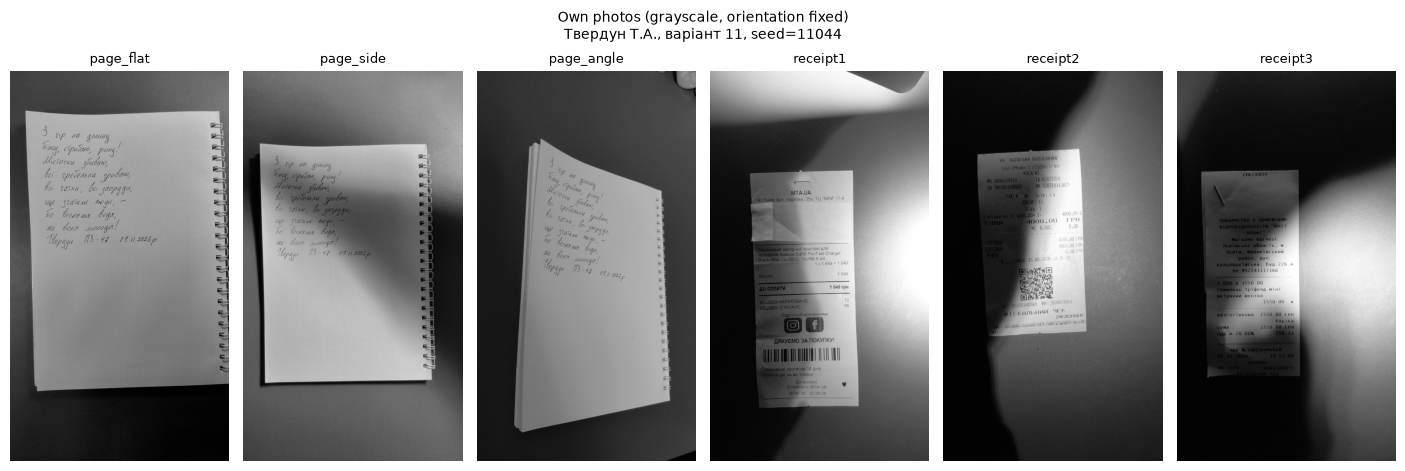

In [36]:
fig, axes = plt.subplots(1, 6, figsize=(14, 4.6), layout="constrained")
for ax, (name, img) in zip(axes, own_imgs.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
fig.suptitle(f"Own photos (grayscale, orientation fixed)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig_own_photos.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Гіпотези

**Г1. Без обробки тінь майже не заважає.** Без попередньої обробки обидва інструменти на синтетичних рядках матимуть CER не більше 5 % без тіні (0 %), а при найсильнішій тіні (75 %) CER виросте не більше ніж на 3 в. п.
*Бо:* навіть у найтемнішому місці фон усе ще помітно світліший за текст, а нейромережі вчилися на фото з нерівним світлом.

**Г2. Оцу не справляється з тінню.** Після бінаризації Оцу CER обох інструментів при тіні 60–75 % буде більше 30 %. Без тіні або зі слабкою тінню (0–15 %) Оцу майже не змінить результат: різниця не більше 1 в. п.
*Бо:* Оцу ставить один поріг на всю картинку, тому затінений фон стає чорним разом із текстом.

**Г3. Адаптивна бінаризація справляється з тінню.** З адаптивною бінаризацією CER на будь-якому рівні тіні буде гіршим, ніж без обробки, не більше ніж на 2 в. п., а при тіні 60–75 % — щонайменше втричі кращим, ніж з Оцу.
*Бо:* адаптивна бінаризація обирає поріг окремо для кожної невеликої ділянки, тож плавна тінь їй не заважає.

**Г4. На справжніх чеках помилок більше.** На фрагментах CORD CER буде у 3–5 разів вищим, ніж на синтетичних рядках без тіні (приблизно 15–25 % проти 3–5 %).
*Бо:* на справжніх фото є розмиття, низька якість, друк з крапок і текстура паперу, а синтетичні рядки ідеально чисті.

**Г5. На власних фото найважчий рукопис.** На фото рукописної сторінки CER обох інструментів буде більше 50 % (найгірше — на фото під кутом). На чеках з тінню CER буде 15–35 %, і адаптивна бінаризація знизить його порівняно з Оцу щонайменше на 10 в. п.
*Бо:* інструменти вчилися на друкованому тексті, а не на рукописі; тінь від руки на чеку — та сама проблема, що й у синтетиці.

**Г6. PaddleOCR кращий на чеках.** На CORD CER PaddleOCR буде нижчим, ніж у EasyOCR, щонайменше на 5 в. п. На українських синтетичних рядках різниця між ними буде меншою за 2 в. п.
*Бо:* PaddleOCR вчили на великій кількості документів і чеків, а чистий друкований рядок обидва інструменти мають читати майже без помилок.

## 7. Попередня обробка

### 7.1. Конфігурації обробки

In [19]:
def preprocess(img, steps=()):
    out = img.copy()
    for step in steps:
        if step == "flatten":
            background = cv2.morphologyEx(out, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
            out = cv2.divide(out, background, scale=255)
        elif step == "clahe":
            out = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(out)
        elif step == "otsu":
            out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
        elif step == "adaptive":
            out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 31, 15)
    return out

PREP = {
    "raw": (),
    "otsu": ("otsu",),
    "adaptive": ("adaptive",),
    "clahe": ("clahe",),
    "flatten": ("flatten",),
    "flatten+otsu": ("flatten", "otsu"),
}
print("Configurations:", list(PREP))

Configurations: ['raw', 'otsu', 'adaptive', 'clahe', 'flatten', 'flatten+otsu']


### 7.2. Приклад обробки рядка з тінню

Otsu threshold at 75 %: 134.0


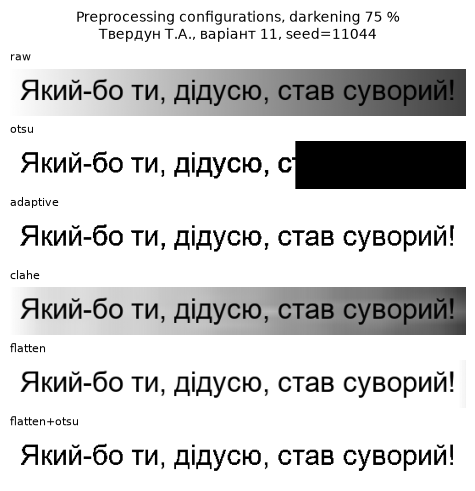

In [20]:
img = cv2.imread(f"data/000_{FACTOR}_75.png", cv2.IMREAD_GRAYSCALE)
print("Otsu threshold at 75 %:", cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0])

fig, axes = plt.subplots(len(PREP), 1, figsize=(8, 0.8 * len(PREP)), layout="constrained")
for ax, (name, steps) in zip(axes, PREP.items()):
    ax.imshow(preprocess(img, steps), cmap="gray", vmin=0, vmax=255)
    ax.set_title(name, fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"Preprocessing configurations, darkening 75 %\n"
             f"{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig_prep_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Розпізнавання

### 8.1. Ініціалізація інструментів

In [23]:
easy = {
    "uk": easyocr.Reader(["uk", "en"], gpu=False, verbose=False),
    "en": easyocr.Reader(["en"], gpu=False, verbose=False),
}

PADDLE_REC = {"uk": "eslav_PP-OCRv5_mobile_rec", "en": "en_PP-OCRv5_mobile_rec"}
paddle = {
    lang: PaddleOCR(
        text_detection_model_name="PP-OCRv5_mobile_det",
        text_recognition_model_name=rec,
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=False,
        enable_mkldnn=False,
    )
    for lang, rec in PADDLE_REC.items()
}
print("OCR engines ready")

Creating model: ('PP-OCRv5_mobile_det', None)
Using official model (PP-OCRv5_mobile_det), the model files will be automatically downloaded and saved in `C:\Users\Tanya\.paddlex\official_models\PP-OCRv5_mobile_det`.
[2026-11-09 20:11:53,295] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/PaddlePaddle/PP-OCRv5_mobile_det/revision/main "HTTP/1.1 200 OK"
[2026-11-09 20:11:53,447] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/PaddlePaddle/PP-OCRv5_mobile_det/tree/0d63e78e2b680928f6b1747d76a08db6e645efb7?recursive=true&expand=false "HTTP/1.1 200 OK"
Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s][2026-11-09 20:11:53,629] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/PaddlePaddle/PP-OCRv5_mobile_det/resolve/0d63e78e2b680928f6b1747d76a08db6e645efb7/.gitattributes "HTTP/1.1 307 Temporary Redirect"
[2026-11-09 20:11:53,690] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/a

OCR engines ready


### 8.2. Функції розпізнавання

In [24]:
def reading_order(boxes, texts):
    items = []
    for box, t in zip(boxes, texts):
        pts = np.asarray(box, dtype=float)
        items.append((pts[:, 1].mean(), pts[:, 0].min(), pts[:, 1].max() - pts[:, 1].min(), t))
    items.sort()
    rows = []
    for cy, x, h, t in items:
        if rows and abs(cy - rows[-1][0]) < h / 2:
            rows[-1][1].append((x, t))
        else:
            rows.append([cy, [(x, t)]])
    return " ".join(t for _, row in rows for _, t in sorted(row))

def ocr_easyocr(img, lang="uk"):
    t0 = time.perf_counter()
    res = easy[lang].readtext(img, detail=1)
    text = reading_order([r[0] for r in res], [r[1] for r in res])
    conf = float(np.mean([r[2] for r in res])) if res else 0.0
    return text, conf, time.perf_counter() - t0

def ocr_paddle(img, lang="uk"):
    t0 = time.perf_counter()
    res = paddle[lang].predict(cv2.cvtColor(img, cv2.COLOR_GRAY2BGR))[0]
    text = reading_order(res["rec_polys"], res["rec_texts"])
    conf = float(np.mean(res["rec_scores"])) if len(res["rec_texts"]) else 0.0
    return text, conf, time.perf_counter() - t0

ENGINES = {"EasyOCR": ocr_easyocr, "PaddleOCR": ocr_paddle}

### 8.3. Перевірка на одному рядку

In [25]:
for lvl in (0, 75):
    img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
    for prep in ("raw", "otsu", "adaptive"):
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(preprocess(img, PREP[prep]))
            print(f"{lvl:2d}% {prep:8s} {eng:9s} {sec:.2f}s conf={conf:.2f} | {text}")
print("Ground truth:", lines[0])

 0% raw      EasyOCR   0.26s conf=0.63 | Який-бо ти; дідусю; став суворий!
 0% raw      PaddleOCR 0.44s conf=0.97 | Який-бо ти, дідусю, став суворий!
 0% otsu     EasyOCR   0.46s conf=0.72 | Який-бо ти, дідусю, став суворий!
 0% otsu     PaddleOCR 0.33s conf=0.97 | Який-бо ти, дідусю, став суворий!
 0% adaptive EasyOCR   0.52s conf=0.82 | Який-бо ТИ; дідусю; став суворий!
 0% adaptive PaddleOCR 0.32s conf=0.99 | Який-бо ти, дідусю, став суворий!
75% raw      EasyOCR   0.45s conf=0.98 | Який-бо ти; дідусю, став суворий!
75% raw      PaddleOCR 0.30s conf=0.97 | Який-бо ти, дідусю, став суворий!
75% otsu     EasyOCR   0.42s conf=0.83 | Який-бо ТИ, дідусю,
75% otsu     PaddleOCR 0.26s conf=1.00 | Який-бо ти, дідусю, с
75% adaptive EasyOCR   0.50s conf=0.69 | Який-бо ТИ, дідусю; став суворий!
75% adaptive PaddleOCR 0.29s conf=0.99 | Який-бо ти, дідусю, став суворий!
Ground truth: Який-бо ти, дідусю, став суворий!


## 9. Метрики

**Метрики.** Обидві рахуються через відстань Левенштейна — мінімальну кількість замін (S), видалень (D) і вставлень (I), щоб із результату OCR отримати еталон:

- CER = (S + D + I) / N, де N — кількість символів еталону;
- WER — та сама формула для слів (N — кількість слів еталону).

**Правила нормалізації**:

1. Unicode NFC — різні записи тієї самої літери (наприклад, «й» одним символом або «и» + знак) зводяться до одного.
2. Апострофи `’ ʼ ‘ ` ´` замінюються на `'` — інакше «м'ята» і «м’ята» вважалися б різними словами.
3. Будь-які послідовності пробілів, табуляцій і переносів рядка замінюються одним пробілом — транскрипції сторінок і чеків мають переноси, а OCR повертає текст через пробіли.
4. **Регістр і розділові знаки не змінюються.** Обґрунтування: у чеках розділові знаки несуть зміст (сума `1550.00`, дата `04.05.2026`, час `19-51-09`), а регістр важливий у кодах і назвах (`CWQTeeMskeM`, `MTA.UA`).

### 9.1. Нормалізація тексту, CER і WER

In [26]:
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"

def normalize(s):
    s = "" if pd.isna(s) else str(s)
    s = unicodedata.normalize("NFC", s)
    for a in APOSTROPHES:
        s = s.replace(a, "'")
    return re.sub(r"\s+", " ", s).strip()

def cer(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

def wer(gt, pred):
    gt, pred = normalize(gt).split(), normalize(pred).split()
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

print("Example from the guide:", round(cer("інженерія даних", "інженерія даиих"), 3),
      round(wer("інженерія даних", "інженерія даиих"), 3))
print("EasyOCR semicolons:", round(cer(lines[0], "Який-бо ти; дідусю; став суворий!"), 3),
      round(wer(lines[0], "Який-бо ти; дідусю; став суворий!"), 3))
print("Otsu cut-off:", round(cer(lines[0], "Який-бо ТИ, дідусю,"), 3))
print("Empty result:", cer(lines[0], ""))

Example from the guide: 0.067 0.5
EasyOCR semicolons: 0.061 0.4
Otsu cut-off: 0.485
Empty result: 1.0


## 10. Експеримент на синтетичних даних

### 10.1. Розпізнавання всіх конфігурацій

In [27]:
rows = []
t_start = time.perf_counter()
for r in ds.itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    for prep_name, steps in PREP.items():
        prepped = preprocess(img, steps)
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(prepped, "uk")
            rows.append({"id": r.id, "level": r.level, "engine": eng, "prep": prep_name,
                         "gt": r.gt, "pred": text, "conf": conf, "sec": sec})
    if (r.Index + 1) % 24 == 0:
        print(f"{r.Index + 1}/{len(ds)} images, {time.perf_counter() - t_start:.0f} s")

res = pd.DataFrame(rows)
res["cer"] = [cer(g, p) for g, p in zip(res["gt"], res["pred"])]
res["wer"] = [wer(g, p) for g, p in zip(res["gt"], res["pred"])]
res.to_csv("data/results_synth.csv", index=False)
print("Runs:", len(res), "| total time:", round(time.perf_counter() - t_start), "s")

24/240 images, 116 s
48/240 images, 244 s
72/240 images, 396 s
96/240 images, 536 s
120/240 images, 691 s
144/240 images, 834 s
168/240 images, 953 s
192/240 images, 1086 s
216/240 images, 1228 s
240/240 images, 1348 s
Runs: 2880 | total time: 1348 s


### 10.2. Зведена таблиця CER

In [28]:
summary = (res.groupby(["engine", "prep", "level"])["cer"].mean()
           .unstack("level") * 100).round(1)
summary

level                    0    15   30   45    60    75
engine    prep                                        
EasyOCR   adaptive      7.2  6.9  6.9  6.6   6.8   6.9
          clahe         6.2  5.8  5.7  5.3   5.3   5.4
          flatten       6.1  6.0  6.0  6.0   6.0   6.1
          flatten+otsu  7.1  7.2  7.2  7.1   7.1   7.1
          otsu          7.1  7.3  7.1  6.8  36.7  45.1
          raw           6.1  6.1  5.9  5.8   5.7   5.9
PaddleOCR adaptive      1.8  1.8  1.7  1.7   1.6   1.8
          clahe         1.6  1.0  1.1  1.5   1.2   1.4
          flatten       1.6  1.6  1.6  1.5   1.6   1.7
          flatten+otsu  1.9  1.8  1.8  1.8   1.8   1.7
          otsu          1.9  2.0  1.9  1.8  32.0  41.4
          raw           1.6  1.0  1.1  1.4   1.4   1.5

### 10.3. Абляційна діаграма

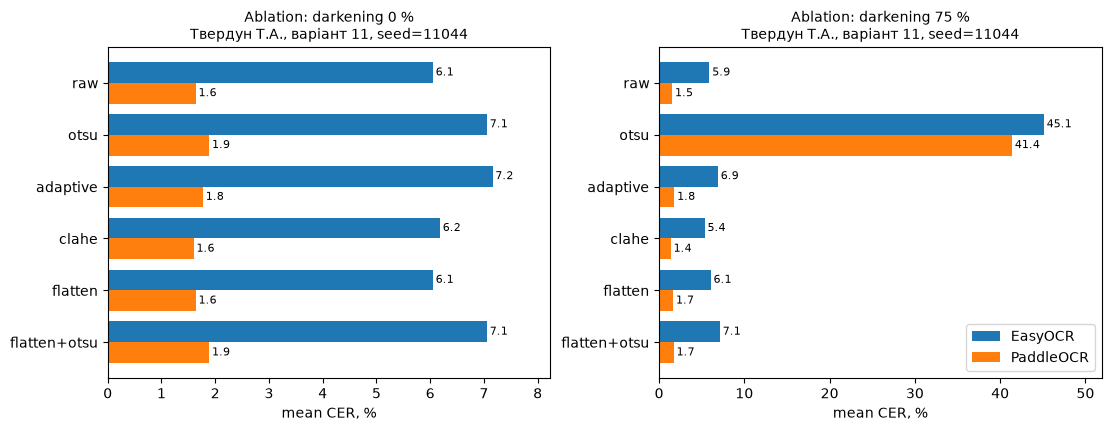

In [29]:
order = list(PREP)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for ax, lvl in zip(axes, (0, 75)):
    sub = (res[res["level"] == lvl].groupby(["prep", "engine"])["cer"].mean()
           .unstack("engine").loc[order] * 100)
    y = np.arange(len(order))
    for k, eng in enumerate(sub.columns):
        bars = ax.barh(y + (k - 0.5) * 0.4, sub[eng], height=0.4, label=eng)
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
    ax.set_yticks(y, order)
    ax.invert_yaxis()
    ax.set_xlabel("mean CER, %")
    ax.margins(x=0.15)
    stamp(ax, f"Ablation: darkening {lvl} %")
axes[1].legend(loc="lower right")
fig.savefig("figures/fig5_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Розпізнавання CORD

### 11.1. Розпізнавання всіх конфігурацій

In [30]:
rows = []
t_start = time.perf_counter()
for r in sample.itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    for prep_name, steps in PREP.items():
        prepped = preprocess(img, steps)
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(prepped, "en")
            rows.append({"receipt": r.receipt, "line": r.line, "seg": r.seg, "category": r.category,
                         "engine": eng, "prep": prep_name, "gt": r.gt, "pred": text,
                         "conf": conf, "sec": sec})
    if (r.Index + 1) % 15 == 0:
        print(f"{r.Index + 1}/{len(sample)} fragments, {time.perf_counter() - t_start:.0f} s")

res_cord = pd.DataFrame(rows)
res_cord["cer"] = [cer(g, p) for g, p in zip(res_cord["gt"], res_cord["pred"])]
res_cord["wer"] = [wer(g, p) for g, p in zip(res_cord["gt"], res_cord["pred"])]
res_cord.to_csv("data/results_cord.csv", index=False)
print("Runs:", len(res_cord), "| total time:", round(time.perf_counter() - t_start), "s")

15/150 fragments, 35 s
30/150 fragments, 73 s
45/150 fragments, 112 s
60/150 fragments, 143 s
75/150 fragments, 181 s
90/150 fragments, 215 s
105/150 fragments, 250 s
120/150 fragments, 291 s
135/150 fragments, 332 s
150/150 fragments, 360 s
Runs: 1800 | total time: 360 s


### 11.2. Зведена таблиця CER

In [31]:
summary_cord = (res_cord.groupby(["engine", "prep"])["cer"].mean()
                .unstack("prep")[list(PREP)] * 100).round(1)
summary_cord

prep,raw,otsu,adaptive,clahe,flatten,flatten+otsu
engine,,,,,,
EasyOCR,26.2,26.2,29.1,25.2,27.8,22.6
PaddleOCR,8.3,13.0,28.5,16.6,10.5,13.8


## 12. Розпізнавання власних фото

### 12.1. Розпізнавання всіх конфігурацій

In [37]:
gt_own = dict(zip(own["name"], own["gt"]))

rows = []
t_start = time.perf_counter()
for name, img in own_imgs.items():
    for prep_name, steps in PREP.items():
        prepped = preprocess(img, steps)
        for eng, fn in ENGINES.items():
            text, conf, sec = fn(prepped, "uk")
            rows.append({"name": name, "engine": eng, "prep": prep_name,
                         "gt": gt_own[name], "pred": text, "conf": conf, "sec": sec})
    print(f"{name} done, {time.perf_counter() - t_start:.0f} s")

res_own = pd.DataFrame(rows)
res_own["cer"] = [cer(g, p) for g, p in zip(res_own["gt"], res_own["pred"])]
res_own["wer"] = [wer(g, p) for g, p in zip(res_own["gt"], res_own["pred"])]
res_own.to_csv("data/results_own.csv", index=False)
print("Runs:", len(res_own), "| total time:", round(time.perf_counter() - t_start), "s")

page_flat done, 147 s
page_side done, 293 s
page_angle done, 435 s
receipt1 done, 602 s
receipt2 done, 775 s
receipt3 done, 949 s
Runs: 72 | total time: 949 s


### 12.2. Зведена таблиця CER

In [38]:
summary_own = (res_own.pivot_table(index=["engine", "name"], columns="prep", values="cer")
               [list(PREP)] * 100).round(1)
summary_own

prep                   raw  otsu  adaptive  clahe  flatten  flatten+otsu
engine    name                                                          
EasyOCR   page_angle  85.4  83.7      93.8   82.6     82.6          83.1
          page_flat   80.3  86.0      79.8   73.0     76.4          77.5
          page_side   91.0  85.4      93.3   87.1     92.1          82.0
          receipt1    10.6  65.5       7.0    8.8      8.8          12.2
          receipt2    60.7  86.4      57.0   52.6     59.5          76.0
          receipt3    30.6  83.4      34.5   24.7     23.4          28.3
PaddleOCR page_angle  69.7  75.3      62.4   66.3     64.0          59.0
          page_flat   28.1  48.9      27.0   25.3     37.6          24.7
          page_side   20.2  72.5      32.6   24.2     28.1          29.2
          receipt1     7.0  56.1       6.0    7.0      7.0           7.0
          receipt2    27.4  88.4      32.6   24.4     25.2          43.7
          receipt3     7.5  76.4      22.6    8.3      9.1          24.4